# Late-Delivery Predictor for an E-commerce Marketplace
**NextGen Institute · Machine Learning · Final Project (Idea 01)**

Dataset: [Brazilian E-Commerce by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle).

**How to run:** download the dataset, unzip the CSV files into a folder called `data/` next to this notebook, then *Restart & Run All*.

## 1 · Problem framing
- **Who has the problem?** An online marketplace (like Noon / Jumia) whose customers get angry when orders arrive after the promised date.
- **Decision supported:** at purchase time, flag risky orders so the company can warn the customer, pick a faster carrier or push the seller.
- **Target:** `is_late = 1` if the order was delivered **after** the estimated delivery date (we create this label).
- **Metric that matters:** the late class is rare (~8%), so **accuracy is misleading**. Missing a late order (false negative) is the costly mistake, so we focus on **recall, PR-AUC and F2**, and tune the decision threshold.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_predict, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             confusion_matrix, classification_report, fbeta_score,
                             recall_score, precision_score, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42
DATA_DIR = Path("data")          # <- put the Olist CSV files here
OUT_DIR = Path("model"); OUT_DIR.mkdir(exist_ok=True)

## 2 · Data understanding
Olist is spread over several related tables. We load the ones we need: orders, items, customers, sellers, products, category translation and geolocation.

In [2]:
def read(name, **kw):
    return pd.read_csv(DATA_DIR / name, **kw)

date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
orders    = read("olist_orders_dataset.csv", parse_dates=date_cols)
items     = read("olist_order_items_dataset.csv")
customers = read("olist_customers_dataset.csv")
sellers   = read("olist_sellers_dataset.csv")
products  = read("olist_products_dataset.csv")
trans     = read("product_category_name_translation.csv")
geo       = read("olist_geolocation_dataset.csv")

for n, d in {"orders": orders, "items": items, "customers": customers, "sellers": sellers,
             "products": products, "translation": trans, "geolocation": geo}.items():
    print(f"{n:12s} rows={len(d):>9,}  cols={d.shape[1]}")

orders       rows=   99,441  cols=8
items        rows=  112,650  cols=7
customers    rows=   99,441  cols=5
sellers      rows=    3,095  cols=4
products     rows=   32,951  cols=9
translation  rows=       71  cols=2
geolocation  rows=1,000,163  cols=5


In [3]:
print(orders.order_status.value_counts())
print("\nMissing values in orders:")
print(orders.isna().sum()[lambda s: s > 0])

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Missing values in orders:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64


## 3 · Building the modelling table (joins + target)
**Leakage rule:** we only use information known **at purchase time**.
We keep: price, freight, items, product size/weight, categories, customer & seller state, distance, the *promised* delivery days, and purchase time.
We **drop**: `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date` and `order_status` — they are only known after the order is processed or delivered.

In [4]:
# 1) Keep only delivered orders (we need the real delivery date to create the label)
df = orders[(orders.order_status == "delivered") & orders.order_delivered_customer_date.notna()].copy()

# 2) Target
df["is_late"] = (df.order_delivered_customer_date > df.order_estimated_delivery_date).astype(int)

# 3) Order-level features known at purchase time
df["promised_days"]  = (df.order_estimated_delivery_date - df.order_purchase_timestamp).dt.total_seconds() / 86400
df["purchase_month"] = df.order_purchase_timestamp.dt.month
df["purchase_dow"]   = df.order_purchase_timestamp.dt.dayofweek
df["purchase_hour"]  = df.order_purchase_timestamp.dt.hour

# 4) Items + products -> aggregate to ONE row per order
products["volume_cm3"] = products.product_length_cm * products.product_height_cm * products.product_width_cm
prod = products.merge(trans, on="product_category_name", how="left")
prod["category"] = prod.product_category_name_english.fillna(prod.product_category_name).fillna("unknown")
it = items.merge(prod[["product_id", "category", "product_weight_g", "volume_cm3", "product_photos_qty"]],
                 on="product_id", how="left")
agg = it.groupby("order_id").agg(
    price=("price", "sum"), freight_value=("freight_value", "sum"),
    n_items=("order_item_id", "count"), n_sellers=("seller_id", "nunique"),
    seller_id=("seller_id", "first"), category=("category", "first"),
    weight_g=("product_weight_g", "sum"), volume_cm3=("volume_cm3", "sum"),
    photos_qty=("product_photos_qty", "mean")).reset_index()

# 5) Customer + seller location
df = (df.merge(agg, on="order_id", how="inner")
        .merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")
        .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left"))

# 6) Distance between customer state and seller state (centroids from the geolocation table)
centroids = geo.groupby("geolocation_state")[["geolocation_lat", "geolocation_lng"]].mean()

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def state_distance(cs, ss):
    a, b = centroids.reindex(cs).values, centroids.reindex(ss).values
    return haversine(a[:, 0], a[:, 1], b[:, 0], b[:, 1])

df["distance_km"] = state_distance(df.customer_state, df.seller_state)
df["same_state"] = (df.customer_state == df.seller_state).astype(int)
df["freight_ratio"] = df.freight_value / df.price.replace(0, np.nan)

# 7) Keep top-30 categories, group the rest
top_cats = df.category.value_counts().head(30).index
df["category"] = df.category.where(df.category.isin(top_cats), "other")

# 8) Basic cleaning
df = df[(df.promised_days > 0) & df.customer_state.notna() & df.seller_state.notna()].reset_index(drop=True)
print("Final modelling table:", df.shape)
print(f"Late-delivery rate: {df.is_late.mean():.2%}")
df.head()

Final modelling table: (96470, 27)
Late-delivery rate: 8.11%


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,is_late,promised_days,purchase_month,purchase_dow,purchase_hour,price,freight_value,n_items,n_sellers,seller_id,category,weight_g,volume_cm3,photos_qty,customer_state,seller_state,distance_km,same_state,freight_ratio
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,0,15.544063,10,0,10,29.99,8.72,1,1,3504c0cb71d7fa48d967e0e4c94d59d9,housewares,500.0,1976.0,4.0,SP,SP,0.000000,1,0.290764
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,0,19.137766,7,1,20,118.70,22.76,1,1,289cdb325fb7e7f891c38608bf9e0962,perfumery,400.0,4693.0,1.0,BA,SP,1375.787736,0,0.191744
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,0,26.639711,8,2,8,159.90,19.22,1,1,4869f7a5dfa277a7dca6462dcf3b52b2,auto,420.0,9576.0,1.0,GO,SP,768.268361,0,0.120200
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,0,26.188819,11,5,19,45.00,27.20,1,1,66922902710d126a0e7d26b0e3805106,pet_shop,450.0,6000.0,3.0,RN,MG,1804.633417,0,0.604444
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,0,12.112049,2,1,21,19.90,8.72,1,1,2c9e548be18521d1c43cde1c582c6de8,stationery,250.0,11475.0,4.0,SP,SP,0.000000,1,0.438191


## 4 · EDA

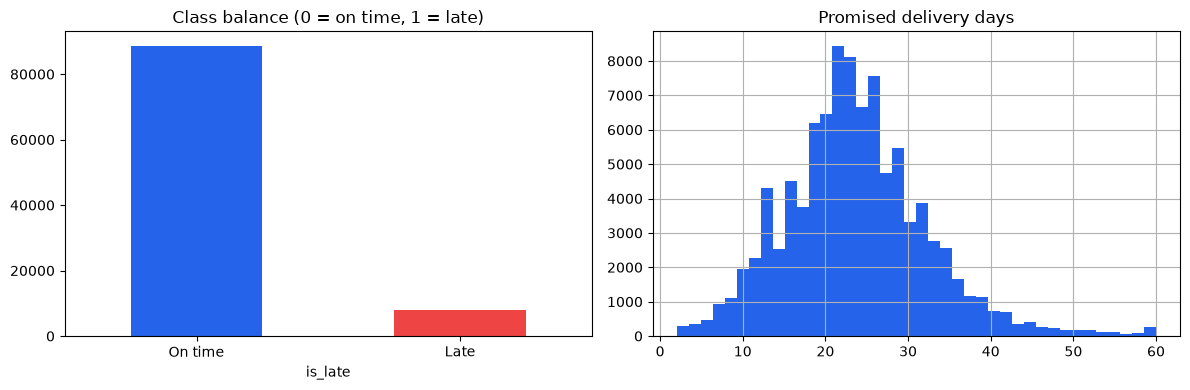

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.is_late.value_counts().sort_index().plot.bar(ax=ax[0], color=["#2563eb", "#ef4444"])
ax[0].set_title("Class balance (0 = on time, 1 = late)"); ax[0].set_xticklabels(["On time", "Late"], rotation=0)
df.promised_days.clip(upper=60).hist(bins=40, ax=ax[1], color="#2563eb")
ax[1].set_title("Promised delivery days"); plt.tight_layout(); plt.show()

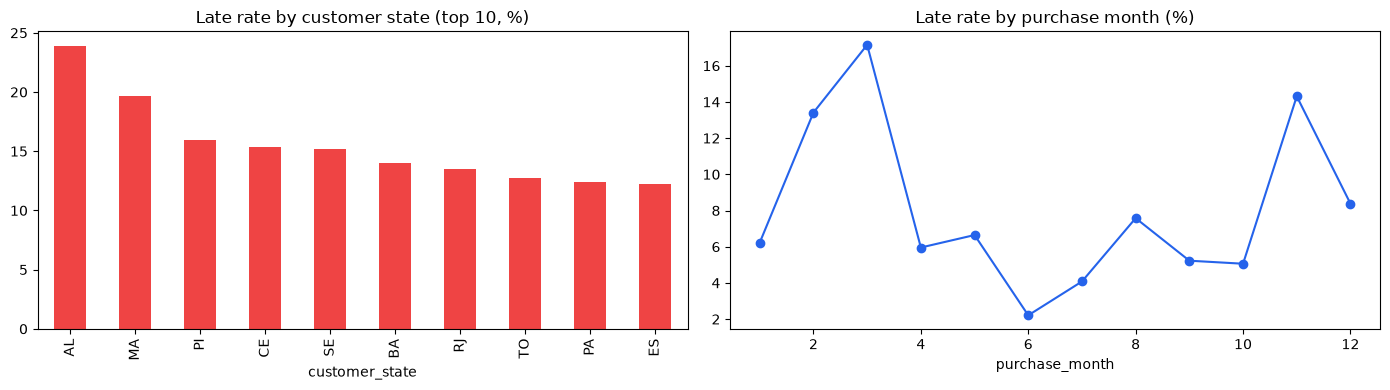

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
(df.groupby("customer_state").is_late.mean().sort_values(ascending=False).head(10) * 100).plot.bar(ax=ax[0], color="#ef4444")
ax[0].set_title("Late rate by customer state (top 10, %)")
(df.groupby("purchase_month").is_late.mean() * 100).plot(ax=ax[1], marker="o", color="#2563eb")
ax[1].set_title("Late rate by purchase month (%)"); plt.tight_layout(); plt.show()

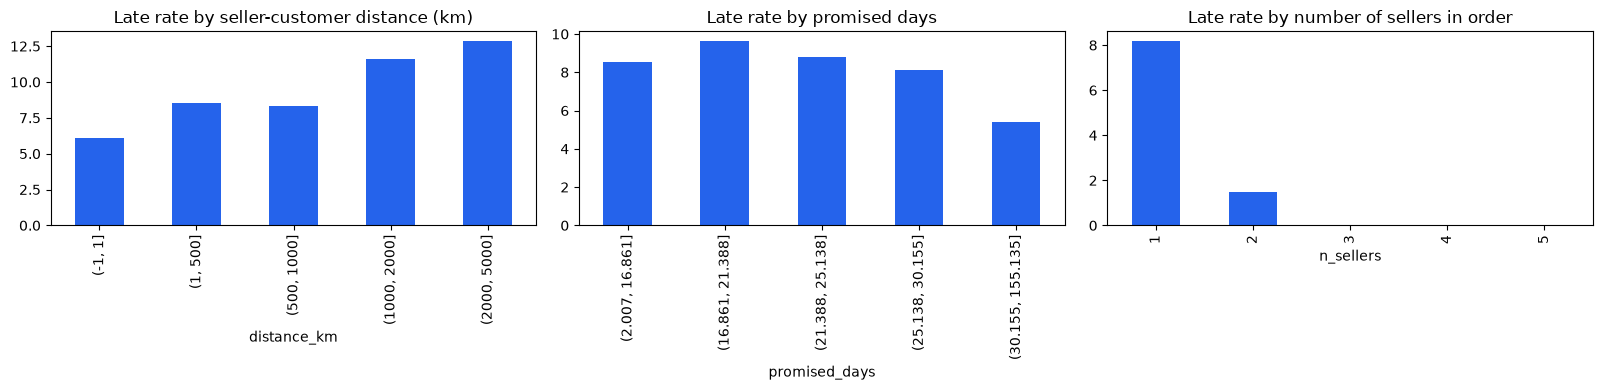

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.groupby(pd.cut(df.distance_km, [-1, 1, 500, 1000, 2000, 5000]), observed=True).is_late.mean().mul(100).plot.bar(ax=ax[0], color="#2563eb")
ax[0].set_title("Late rate by seller-customer distance (km)")
df.groupby(pd.qcut(df.promised_days, 5, duplicates="drop"), observed=True).is_late.mean().mul(100).plot.bar(ax=ax[1], color="#2563eb")
ax[1].set_title("Late rate by promised days")
df.groupby("n_sellers").is_late.mean().mul(100).plot.bar(ax=ax[2], color="#2563eb")
ax[2].set_title("Late rate by number of sellers in order"); plt.tight_layout(); plt.show()

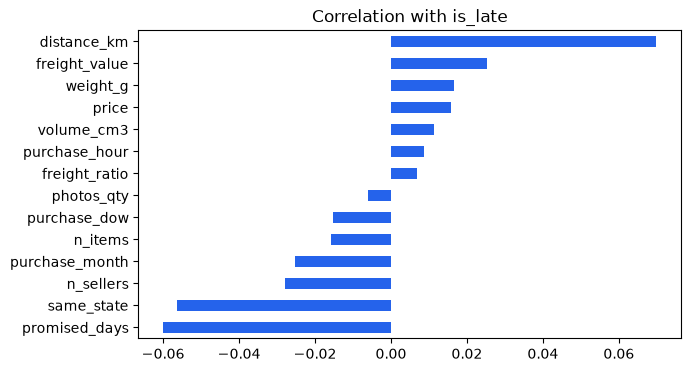

In [8]:
num_cols = ["price", "freight_value", "freight_ratio", "n_items", "n_sellers", "weight_g", "volume_cm3",
            "photos_qty", "distance_km", "same_state", "promised_days", "purchase_month", "purchase_dow", "purchase_hour"]
corr = df[num_cols + ["is_late"]].corr()["is_late"].drop("is_late").sort_values()
corr.plot.barh(figsize=(7, 4), color="#2563eb"); plt.title("Correlation with is_late"); plt.show()

### EDA insights (write your own conclusions from the charts above)
1. The late class is rare (~8%), so accuracy alone would be misleading → use recall / PR-AUC and a tuned threshold.
2. Late rate differs a lot between customer states — remote states are riskier.
3. Longer seller→customer distance and multi-seller orders are riskier.
4. Late rate is not flat across the year (peak periods such as Nov–Mar stress carriers).
5. A longer *promised* delivery window gives more buffer, so it lowers late risk.

## 5 · Preprocessing (inside a scikit-learn Pipeline) and split
We **split first**, then fit every transformer on the training data only (no leakage).

In [9]:
num_features = ["price", "freight_value", "freight_ratio", "n_items", "n_sellers", "weight_g", "volume_cm3",
                "photos_qty", "distance_km", "same_state", "promised_days", "purchase_month", "purchase_dow", "purchase_hour"]
cat_features = ["category", "customer_state", "seller_state"]
FEATURES = num_features + cat_features

X, y = df[FEATURES], df["is_late"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape, f"| late rate train {y_train.mean():.3%} test {y_test.mean():.3%}")

def make_preprocessor(scale=False):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_features),
    ])

(77176, 17) (19294, 17) | late rate train 8.113% test 8.111%


## 6 · Modeling — baseline + 3 algorithms
We compare a majority-class baseline with Logistic Regression, Random Forest and Gradient Boosting. Class imbalance is handled with `class_weight="balanced"`.

In [10]:
models = {
    "Baseline (majority)": Pipeline([("prep", make_preprocessor()), ("m", DummyClassifier(strategy="prior"))]),
    "Logistic Regression": Pipeline([("prep", make_preprocessor(scale=True)),
                                     ("m", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Random Forest": Pipeline([("prep", make_preprocessor()),
                               ("m", RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=5,
                                                            class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))]),
    "Gradient Boosting": Pipeline([("prep", make_preprocessor()),
                                   ("m", HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
}

skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, pipe in models.items():
    proba = cross_val_predict(pipe, X_train, y_train, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
    rows.append({"model": name, "CV ROC-AUC": roc_auc_score(y_train, proba),
                 "CV PR-AUC": average_precision_score(y_train, proba)})
cv_results = pd.DataFrame(rows).set_index("model").round(4)
cv_results

,CV ROC-AUC,CV PR-AUC
model,,
Baseline (majority),0.4999,0.0811
Logistic Regression,0.7065,0.1804
Random Forest,0.7581,0.2587
Gradient Boosting,0.7850,0.2834


## 7 · Hyperparameter tuning (training data only)
We tune the best family with randomized search + cross-validation, optimising PR-AUC.

In [11]:
best_name = cv_results["CV PR-AUC"].drop("Baseline (majority)").idxmax()
print("Best family in CV:", best_name)

param_spaces = {
    "Gradient Boosting": {"m__learning_rate": [0.03, 0.05, 0.1], "m__max_depth": [3, 5, 8, None],
                          "m__max_leaf_nodes": [15, 31, 63], "m__min_samples_leaf": [20, 50, 100],
                          "m__l2_regularization": [0.0, 0.1, 1.0], "m__max_iter": [150, 300]},
    "Random Forest": {"m__n_estimators": [200, 300], "m__max_depth": [8, 12, 16, None],
                      "m__min_samples_leaf": [2, 5, 10], "m__max_features": ["sqrt", 0.5]},
    "Logistic Regression": {"m__C": [0.01, 0.1, 1, 10]},
}
search = RandomizedSearchCV(models[best_name], param_spaces[best_name], n_iter=8, cv=3,
                            scoring="average_precision", n_jobs=-1, random_state=RANDOM_STATE)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)
print(f"Best CV PR-AUC: {search.best_score_:.4f}")
best_model = search.best_estimator_

Best family in CV: Gradient Boosting
Best params: {'m__min_samples_leaf': 100, 'm__max_leaf_nodes': 31, 'm__max_iter': 150, 'm__max_depth': None, 'm__learning_rate': 0.05, 'm__l2_regularization': 0.0}
Best CV PR-AUC: 0.2794


### Choosing the decision threshold
The default 0.5 threshold is wrong for a rare class. We pick the threshold that maximises **F2** (recall counts twice as much as precision), using **out-of-fold predictions on the training set only**.

In [12]:
oof = cross_val_predict(best_model, X_train, y_train, cv=3, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f2 = (5 * prec * rec) / (4 * prec + rec + 1e-12)
THRESHOLD = float(thr[np.argmax(f2[:-1])])
print(f"Chosen threshold: {THRESHOLD:.3f}")

Chosen threshold: 0.496


## 8 · Final evaluation on the untouched test set

In [13]:
def evaluate(model, thr=0.5):
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p),
            "Recall": recall_score(y_test, pred), "Precision": precision_score(y_test, pred, zero_division=0),
            "F2": fbeta_score(y_test, pred, beta=2)}

baseline = models["Baseline (majority)"].fit(X_train, y_train)
results = pd.DataFrame({"Baseline (majority)": evaluate(baseline),
                        f"Tuned {best_name} @0.5": evaluate(best_model, 0.5),
                        f"Tuned {best_name} @{THRESHOLD:.2f}": evaluate(best_model, THRESHOLD)}).T.round(3)
results

,ROC-AUC,PR-AUC,Recall,Precision,F2
Baseline (majority),0.500,0.081,0.000,0.000,0.000
Tuned Gradient Boosting @0.5,0.787,0.287,0.677,0.196,0.454
Tuned Gradient Boosting @0.50,0.787,0.287,0.681,0.195,0.454


              precision    recall  f1-score   support

     On time       0.96      0.75      0.84     17729
        Late       0.19      0.68      0.30      1565

    accuracy                           0.75     19294
   macro avg       0.58      0.72      0.57     19294
weighted avg       0.90      0.75      0.80     19294



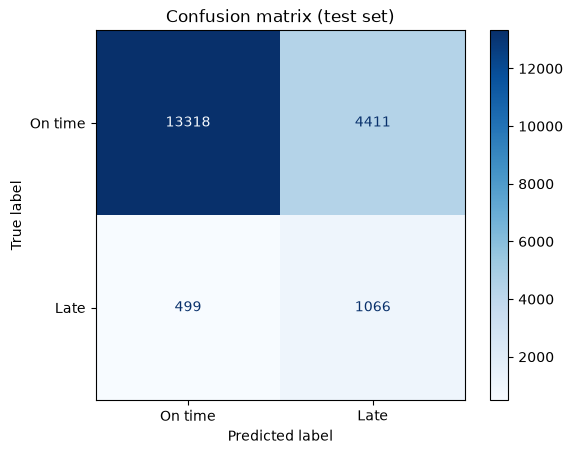

In [14]:
p_test = best_model.predict_proba(X_test)[:, 1]
pred_test = (p_test >= THRESHOLD).astype(int)
print(classification_report(y_test, pred_test, target_names=["On time", "Late"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=["On time", "Late"]).plot(cmap="Blues")
plt.title("Confusion matrix (test set)"); plt.show()

### Error analysis & feature importance

States where the model misses the most late orders:


,orders,late_rate,recall
customer_state,,,
PB,102.0,0.098,0.500
SP,8062.0,0.061,0.500
PR,967.0,0.060,0.517
MT,186.0,0.070,0.615
SC,725.0,0.086,0.629
MG,2219.0,0.053,0.636
PE,310.0,0.135,0.643
GO,401.0,0.080,0.688


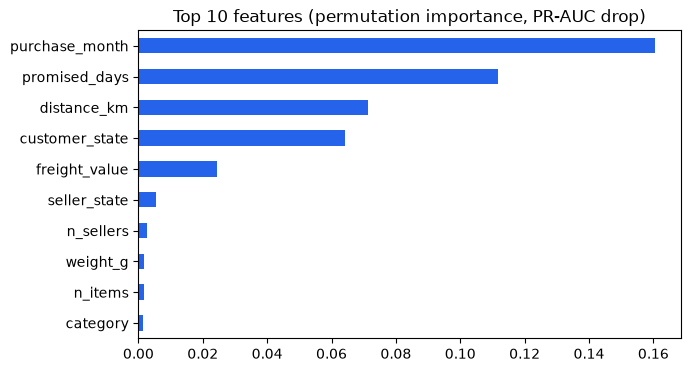

In [15]:
err = X_test.copy(); err["y"] = y_test.values; err["pred"] = pred_test; err["proba"] = p_test
by_state = (err.groupby("customer_state")
              .apply(lambda g: pd.Series({"orders": len(g), "late_rate": g.y.mean(),
                                          "recall": recall_score(g.y, g.pred) if g.y.sum() else np.nan}))
              .query("orders >= 100").sort_values("recall"))
print("States where the model misses the most late orders:")
display(by_state.head(8).round(3))

sample = X_test.sample(min(4000, len(X_test)), random_state=RANDOM_STATE)
pi = permutation_importance(best_model, sample, y_test.loc[sample.index], scoring="average_precision",
                            n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
pd.Series(pi.importances_mean, index=FEATURES).sort_values().tail(10).plot.barh(figsize=(7, 4), color="#2563eb")
plt.title("Top 10 features (permutation importance, PR-AUC drop)"); plt.show()

## 9 · Business insight
*(Replace the numbers with your own results from the tables above.)*
- With the tuned threshold the model catches **[recall]%** of late orders at **[precision]%** precision — far better than the baseline that catches none.
- **Action:** orders above the threshold get a proactive "may arrive late" message and priority handling with the carrier; high-risk sellers are reviewed.
- **Limitations:** the data is from Brazil (2016–2018); distance uses state centroids, not exact addresses; we ignore carrier capacity, weather and strikes; probabilities from a `balanced` model are not calibrated.

With the tuned threshold (0.50) the model catches 68% of late orders at 19.5% precision, about 2.4x the 8.1% base late rate. The company can send a proactive “may arrive late” message and prioritise these orders with carriers. Limitation: 4 out of 5 flagged orders arrive on time, so the action should be cheap (a notification, not a refund).

## 10 · Save artifacts for the web app

In [16]:
# Seller late-rate table (seller page in the app)
seller_stats = (df.groupby("seller_id").agg(orders=("is_late", "size"), late_orders=("is_late", "sum"),
                                            late_rate=("is_late", "mean"), seller_state=("seller_state", "first"),
                                            avg_price=("price", "mean")).reset_index())
seller_stats = seller_stats[seller_stats.orders >= 10].sort_values("late_rate", ascending=False)
seller_stats.to_csv(OUT_DIR / "seller_stats.csv", index=False)

meta = {
    "threshold": THRESHOLD,
    "model_name": best_name,
    "metrics": {k: round(float(v), 4) for k, v in evaluate(best_model, THRESHOLD).items()},
    "categories": sorted(df.category.unique().tolist()),
    "customer_states": sorted(df.customer_state.unique().tolist()),
    "seller_states": sorted(df.seller_state.unique().tolist()),
    "centroids": {s: [float(r.geolocation_lat), float(r.geolocation_lng)] for s, r in centroids.iterrows()},
    "defaults": {"weight_g": float(df.weight_g.median()), "volume_cm3": float(df.volume_cm3.median()),
                 "photos_qty": float(df.photos_qty.median())},
    "base_late_rate": float(df.is_late.mean()),
}
joblib.dump(best_model, OUT_DIR / "pipeline.joblib")
json.dump(meta, open(OUT_DIR / "meta.json", "w"))
print("Saved:", [p.name for p in OUT_DIR.iterdir()])

Saved: ['meta.json', 'pipeline.joblib', 'seller_stats.csv']


## 11 · Stretch goal — how much does lateness hurt customer reviews?
(Needs `olist_order_reviews_dataset.csv`. Skipped automatically if the file is missing.)

In [17]:
rev_path = DATA_DIR / "olist_order_reviews_dataset.csv"
if rev_path.exists():
    rev = pd.read_csv(rev_path)[["order_id", "review_score"]].drop_duplicates("order_id")
    r = df[["order_id", "is_late"]].merge(rev, on="order_id")
    print(r.groupby("is_late").review_score.mean().rename({0: "On time", 1: "Late"}).round(2))
    print(f"Share of 1-2 star reviews -> on time: {(r[r.is_late==0].review_score<=2).mean():.1%} | late: {(r[r.is_late==1].review_score<=2).mean():.1%}")
else:
    print("Reviews file not found - skipping.")

is_late
On time    4.29
Late       2.57
Name: review_score, dtype: float64
Share of 1-2 star reviews -> on time: 9.2% | late: 54.1%


## 12 · CV bullet & credits
> Built a late-delivery prediction model on ~[N] real marketplace orders across [N] joined tables, deployed as an order-risk app (recall [X]%, PR-AUC [X]).

Dataset: Olist, *Brazilian E-Commerce Public Dataset* — https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

In [18]:
import sklearn; print(sklearn.__version__)

1.6.1


In [1]:
   import sys; print(sys.executable)

c:\Users\ASUS\AppData\Local\Programs\Python\Python311\python.exe
